# Clasificación geomecánica RMR / GSI — análisis y control de calidad

**Datos:** estudio de campo 2023 publicado por UCSC (dataset público de terceros), 79 macizos rocosos, anonimizados (`Macizo_01 … Macizo_79`).
**Objetivo:** validar los datos (QA/QC), verificar el cálculo del RMR, explorar su relación con el GSI y la calidad de roca, y exportar una tabla limpia para Power BI.

> Citar la fuente original al publicar y revisar sus términos de uso.

## 1. Configuración y carga

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

BASE = Path("..")                       # carpeta del proyecto (este notebook está en /notebooks)
DATA = BASE / "data" / "macizos.xlsx"
OUT  = BASE / "output"
OUT.mkdir(exist_ok=True)

df = pd.read_excel(DATA, sheet_name="Datos")
print(f"{df.shape[0]} macizos, {df.shape[1]} columnas")
df.head()

79 macizos, 22 columnas


,id_macizo,litologia,resistencia_UCS,RQD_puntaje,espaciamiento,condicion_discont,agua,RMR,GSI,clase_RMR,...,R4c_rugosidad,R4d_relleno,R4e_alteracion,UCS_MPa,RQD,Q,ajuste_SMR,SMR,RMR_fuente,dif_RMR_vs_fuente
0,Macizo_01,"Metasedimentaria (wacka, lutita, pizarra)",4,3,5,14.5,7.0,33.5,35,IV - Mala,...,2.5,4,3.0,48.874217,0.10,0.186667,15.0,48.5,33.5,0
1,Macizo_02,"Metasedimentaria (wacka, lutita, pizarra)",7,3,5,14.0,7.0,36.0,45,IV - Mala,...,1.0,6,5.0,92.319003,0.20,0.066667,-27.5,8.5,36.0,0
2,Macizo_03,"Metasedimentaria (wacka, lutita, pizarra)",12,8,5,19.0,7.0,51.0,45,III - Regular,...,5.0,6,5.0,132.026149,0.35,0.400000,15.0,66.0,51.0,0
3,Macizo_04,"Metasedimentaria (wacka, lutita, pizarra)",12,8,5,15.0,7.0,47.0,45,III - Regular,...,1.0,6,5.0,101.291247,0.40,0.133333,15.0,62.0,47.0,0
4,Macizo_05,"Metasedimentaria (wacka, lutita, pizarra)",2,3,5,15.0,7.0,32.0,30,IV - Mala,...,3.0,5,4.0,23.271979,0.00,0.237037,15.0,47.0,32.0,0


## 2. Control de calidad (QA/QC)

Se revisan: duplicados, vacíos, rangos válidos y consistencia del RMR. Cada chequeo devuelve **OK / REVISAR** para dejar la validación documentada.

In [2]:
# Puntajes mínimo y máximo del RMR (Bieniawski 1989) por parámetro
rangos = {
    "resistencia_UCS":   (0, 15),
    "RQD_puntaje":       (3, 20),
    "espaciamiento":     (5, 20),
    "condicion_discont": (0, 30),
    "agua":              (0, 15),
}
rangos_otros = {"RMR": (0, 100), "GSI": (0, 100), "RQD": (0, 1), "UCS_MPa": (0, np.inf)}

chequeos = []
chequeos.append(("IDs únicos", df["id_macizo"].is_unique))
cols_clave = ["id_macizo", "litologia", *rangos, "RMR", "GSI", "UCS_MPa", "RQD"]
chequeos.append(("Sin vacíos en columnas clave", int(df[cols_clave].isna().sum().sum()) == 0))
for c, (lo, hi) in {**rangos, **rangos_otros}.items():
    chequeos.append((f"{c} dentro de [{lo}, {hi}]", bool(df[c].between(lo, hi).all())))

qa = pd.DataFrame(chequeos, columns=["chequeo", "ok"])
qa["resultado"] = np.where(qa["ok"], "OK", "REVISAR")
qa[["chequeo", "resultado"]]

,chequeo,resultado
0,IDs únicos,OK
1,Sin vacíos en columnas clave,OK
2,"resistencia_UCS dentro de [0, 15]",OK
3,"RQD_puntaje dentro de [3, 20]",OK
4,"espaciamiento dentro de [5, 20]",OK
5,"condicion_discont dentro de [0, 30]",OK
6,"agua dentro de [0, 15]",OK
7,"RMR dentro de [0, 100]",OK
8,"GSI dentro de [0, 100]",OK
9,"RQD dentro de [0, 1]",OK


In [3]:
assert qa["ok"].all(), "Hay chequeos en REVISAR: corregir antes de continuar"
print("Todos los chequeos de rango y completitud pasan.")

Todos los chequeos de rango y completitud pasan.


### 2.1 Verificación del cálculo del RMR

En estos datos el **RMR básico** es la suma de los 5 puntajes (UCS, RQD, espaciamiento, condición de discontinuidades y agua), **sin** ajuste por orientación.
Se recalcula en Python y se compara con el RMR calculado por la fuente (`RMR_fuente`).

In [4]:
params = list(rangos)                                  # los 5 puntajes
df["RMR_py"] = df[params].sum(axis=1)

dif_fuente = (df["RMR_py"] - df["RMR_fuente"]).abs()
dif_excel  = (df["RMR_py"] - df["RMR"]).abs()
print("Macizos con RMR distinto al de la fuente:", int((dif_fuente > 1e-6).sum()))
print("Macizos con RMR distinto al calculado en el Excel:", int((dif_excel > 1e-6).sum()))

# SMR = RMR + ajuste (orientación de juntas y método de excavación, dato de la fuente)
print("Macizos con SMR inconsistente:", int(((df["RMR_py"] + df["ajuste_SMR"] - df["SMR"]).abs() > 1e-6).sum()))

Macizos con RMR distinto al de la fuente: 0
Macizos con RMR distinto al calculado en el Excel: 0
Macizos con SMR inconsistente: 0


### 2.2 Clasificación de calidad (Bieniawski)
Clases: I (>80), II (>60), III (>40), IV (>20), V (≤20). Se recalcula y se compara con la columna del Excel.

In [5]:
orden_clases = ["I - Muy buena", "II - Buena", "III - Regular", "IV - Mala", "V - Muy mala"]

def clase_rmr(x):
    if x > 80: return orden_clases[0]
    if x > 60: return orden_clases[1]
    if x > 40: return orden_clases[2]
    if x > 20: return orden_clases[3]
    return orden_clases[4]

df["clase_RMR_py"] = df["RMR_py"].apply(clase_rmr)
print("Clases distintas a las del Excel:", int((df["clase_RMR_py"] != df["clase_RMR"]).sum()))
df["clase_RMR_py"].value_counts().reindex(orden_clases, fill_value=0)

Clases distintas a las del Excel: 0


clase_RMR_py
I - Muy buena     0
II - Buena        0
III - Regular    52
IV - Mala        27
V - Muy mala      0
Name: count, dtype: int64

## 3. Estadística descriptiva

In [6]:
vars_num = ["RMR", "GSI", "UCS_MPa", "RQD", "Q", "SMR"]
df[vars_num].describe().round(2)

,RMR,GSI,UCS_MPa,RQD,Q,SMR
count,79.00,79.00,79.00,79.00,79.00,79.00
mean,43.20,44.37,90.99,0.30,0.37,55.00
std,7.59,11.16,47.68,0.22,0.43,10.91
min,28.00,15.00,17.62,0.00,0.04,8.50
25%,38.50,35.00,59.03,0.12,0.14,49.00
50%,43.00,45.00,84.14,0.28,0.21,57.00
75%,48.75,50.00,113.98,0.41,0.39,61.94
max,59.00,65.00,288.22,0.90,2.19,72.86


In [7]:
# Por litología. Ojo con n: grupos muy pequeños son solo orientativos.
por_lito = (df.groupby("litologia")
              .agg(n=("id_macizo", "count"),
                   RMR_medio=("RMR_py", "mean"), RMR_min=("RMR_py", "min"), RMR_max=("RMR_py", "max"),
                   GSI_medio=("GSI", "mean"), UCS_medio_MPa=("UCS_MPa", "mean"))
              .round(1))
por_lito

,n,RMR_medio,RMR_min,RMR_max,GSI_medio,UCS_medio_MPa
litologia,,,,,,
Granitoide,7,48.2,32.0,59.0,60.0,98.2
"Metasedimentaria (wacka, lutita, pizarra)",69,42.7,28.0,58.0,42.8,89.5
Volcánica / básica,3,42.7,28.0,55.0,43.3,107.4


## 4. Relación entre RMR y GSI

Se usan ambos coeficientes: Pearson (relación lineal) y Spearman (relación de orden, menos sensible a valores extremos).

In [8]:
pearson  = df["RMR_py"].corr(df["GSI"], method="pearson")
spearman = df["RMR_py"].corr(df["GSI"], method="spearman")
print(f"Pearson  RMR vs GSI: {pearson:.2f}")
print(f"Spearman RMR vs GSI: {spearman:.2f}")

# Recta de ajuste simple (descriptiva)
pend, orig = np.polyfit(df["GSI"], df["RMR_py"], 1)
print(f"RMR ≈ {pend:.2f}·GSI + {orig:.1f}   (R² = {pearson**2:.2f})")

Pearson  RMR vs GSI: 0.63
Spearman RMR vs GSI: 0.63
RMR ≈ 0.43·GSI + 24.2   (R² = 0.39)


## 5. Gráficos

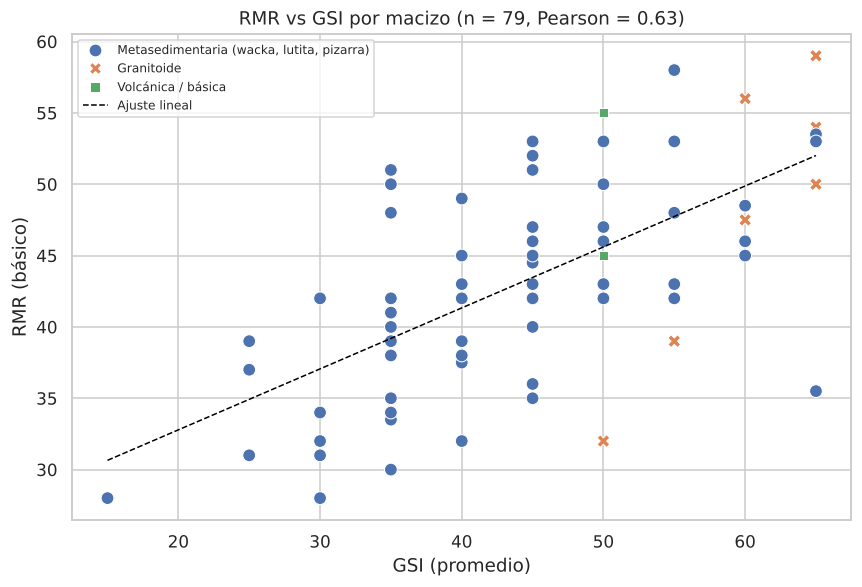

In [9]:
# 5.1 Dispersión RMR vs GSI por litología
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="GSI", y="RMR_py", hue="litologia", style="litologia", s=70, ax=ax)
xs = np.linspace(df["GSI"].min(), df["GSI"].max(), 50)
ax.plot(xs, pend * xs + orig, color="black", lw=1, ls="--", label="Ajuste lineal")
ax.set(title=f"RMR vs GSI por macizo (n = {len(df)}, Pearson = {pearson:.2f})", xlabel="GSI (promedio)", ylabel="RMR (básico)")
ax.legend(title="", fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "01_rmr_vs_gsi.png"); plt.show()

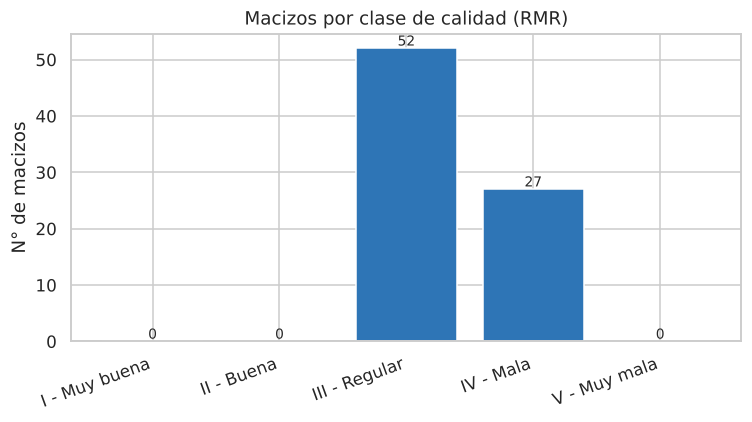

In [10]:
# 5.2 Macizos por clase de calidad
conteo = df["clase_RMR_py"].value_counts().reindex(orden_clases, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(conteo.index, conteo.values, color="#2E75B6")
for i, v in enumerate(conteo.values):
    ax.text(i, v + 0.5, str(v), ha="center", fontsize=9)
ax.set(title="Macizos por clase de calidad (RMR)", ylabel="N° de macizos")
plt.xticks(rotation=20, ha="right")
fig.tight_layout(); fig.savefig(OUT / "02_clases_rmr.png"); plt.show()

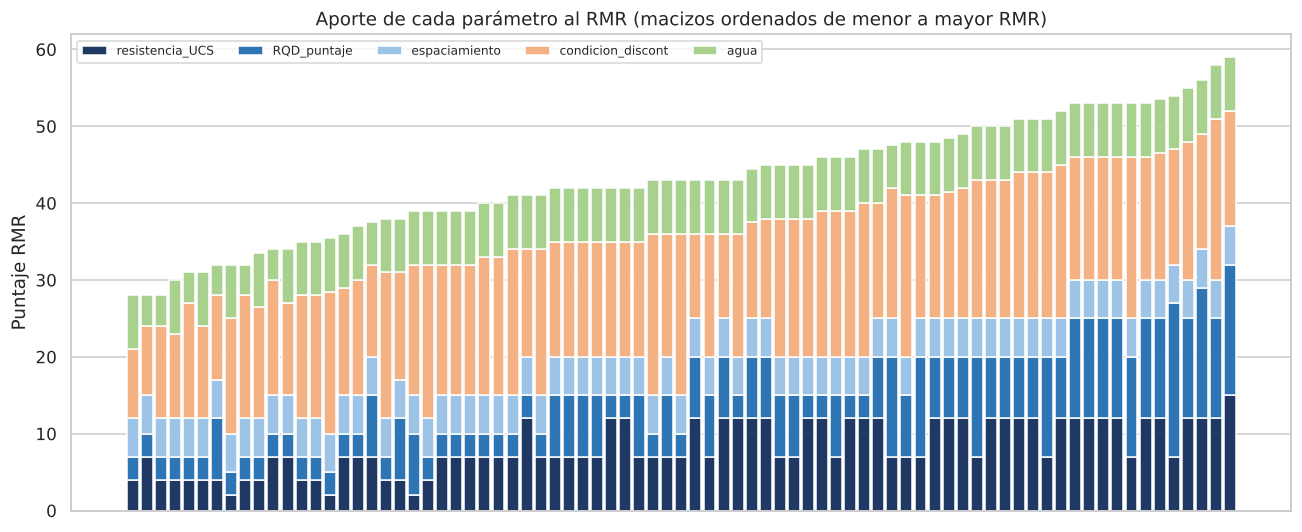

In [11]:
# 5.3 Aporte de cada parámetro al RMR, macizos ordenados por RMR
orden = df.sort_values("RMR_py")
fig, ax = plt.subplots(figsize=(12, 5))
base = np.zeros(len(orden))
colores = ["#1F3864", "#2E75B6", "#9DC3E6", "#F4B183", "#A9D18E"]
for p, col in zip(params, colores):
    ax.bar(orden["id_macizo"], orden[p], bottom=base, label=p, color=col, width=0.85)
    base += orden[p].values
ax.set(title="Aporte de cada parámetro al RMR (macizos ordenados de menor a mayor RMR)", ylabel="Puntaje RMR")
ax.set_xticks([]); ax.legend(ncol=5, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "03_aporte_parametros.png"); plt.show()

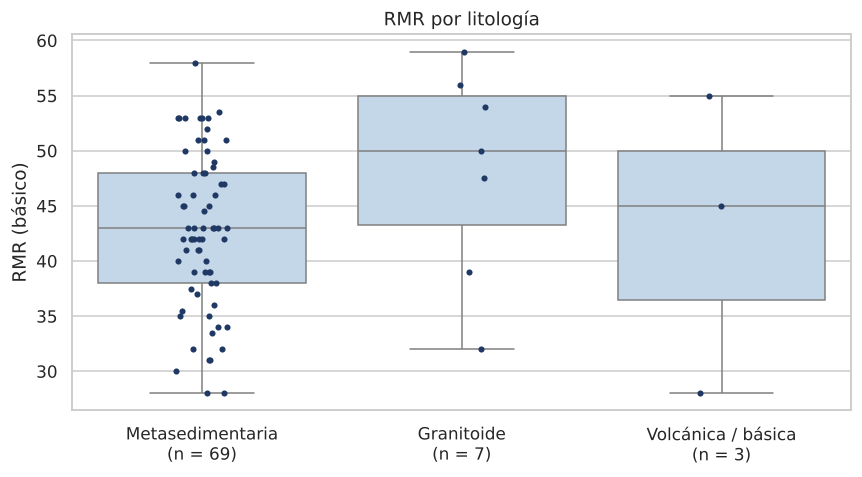

In [12]:
# 5.4 RMR por litología (con n en la etiqueta)
etq = {k: f"{k.split(' (')[0]}\n(n = {v})" for k, v in df["litologia"].value_counts().items()}
d2 = df.assign(lito_n=df["litologia"].map(etq))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=d2, x="lito_n", y="RMR_py", color="#BDD7EE", ax=ax, showfliers=False)
sns.stripplot(data=d2, x="lito_n", y="RMR_py", color="#1F3864", size=4, ax=ax)
ax.set(title="RMR por litología", xlabel="", ylabel="RMR (básico)")
fig.tight_layout(); fig.savefig(OUT / "04_rmr_por_litologia.png"); plt.show()

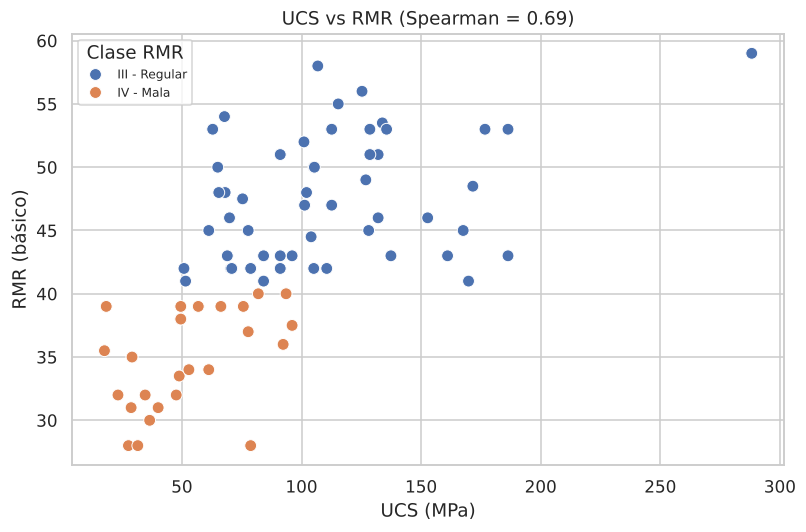

In [13]:
# 5.5 Resistencia de roca intacta (UCS) vs RMR
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.scatterplot(data=df, x="UCS_MPa", y="RMR_py", hue="clase_RMR_py", hue_order=orden_clases[2:4], s=60, ax=ax)
r_ucs = df["UCS_MPa"].corr(df["RMR_py"], method="spearman")
ax.set(title=f"UCS vs RMR (Spearman = {r_ucs:.2f})", xlabel="UCS (MPa)", ylabel="RMR (básico)")
ax.legend(title="Clase RMR", fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "05_ucs_vs_rmr.png"); plt.show()

## 6. Exportar para Power BI

Power BI puede leer directamente `macizos.xlsx`. Este CSV es opcional y deja los valores ya verificados en Python.

In [14]:
export = df[["id_macizo", "litologia", *params, "RMR_py", "clase_RMR_py", "GSI",
             "UCS_MPa", "RQD", "Q", "ajuste_SMR", "SMR"]].rename(
    columns={"RMR_py": "RMR", "clase_RMR_py": "clase_RMR"})
export.to_csv(OUT / "macizos_procesados.csv", index=False, encoding="utf-8-sig")
print(f"Exportado: {OUT / 'macizos_procesados.csv'}  ({len(export)} filas)")

Exportado: ../output/macizos_procesados.csv  (79 filas)


## 7. Limitaciones a declarar

- **Datos públicos de terceros** (no de proyectos propios); el análisis es de exploración y de control de calidad, no una evaluación geotécnica de diseño.
- **RMR básico**: sin ajuste por orientación de discontinuidades. El `SMR` usa el ajuste informado por la fuente.
- **Granitoides (n = 7) y rocas volcánicas (n = 3)**: pocos casos, sus promedios son solo orientativos.
- **`espaciamiento` es constante (5)** en todos los macizos; no aporta variación.
- **`litologia` es una clasificación simplificada** hecha por palabras clave de la descripción original.
- **No hay volumen explotable** en estos datos.
- Las correlaciones describen la muestra; no implican causalidad.